# Лабораторная работа №1: Первичное исследование и оценка качества данных

**Датасет:** `flavors_of_cacao.csv`  



# 1. Постановка задачи (Business Understanding)

## 1.1. Что это за данные
Датасет содержит информацию о дегустационных обзорах шоколада от различных производителей по всему миру. В данных представлены такие характеристики, как компания-производитель, страна производства, процент содержания какао, дата обзора, рейтинг и происхождение какао-бобов. Каждая строка — это отдельный обзор конкретного шоколадного батончика. Данные охватывают период с 2006 по 2017 год.

## 1.2. Условный заказчик
Условным заказчиком может выступать **отдел закупок крупной сети магазинов деликатесов** или **маркетинговое агентство**, специализирующееся на продуктах питания. Также это может быть команда продукта интернет-магазина, которая хочет подбирать ассортимент на основе данных о рейтингах и предпочтениях.

## 1.3. Задачи интеллектуального анализа данных (ИАД)

1. **Регрессия**: Прогнозирование рейтинга шоколада (Rating) на основе процента содержания какао (Cocoa Percent), страны производителя и типа бобов.
2. **Кластеризация**: Сегментация производителей шоколада по среднему рейтингу и ассортименту выпускаемой продукции.
3. **Поиск аномалий**: Выявление батончиков с экстремально низкими или высокими оценками при высоком содержании какао.
4. **Описательная аналитика**: Изучение распределения рейтингов по странам и типам какао-бобов.


In [1]:
!pip install pandas numpy matplotlib seaborn scipy


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


sns.set_theme(style="whitegrid")
%matplotlib inline


pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)


# 2. Паспорт датасета (Data Understanding)


In [3]:

df = pd.read_csv('../data/flavors_of_cacao.csv')

df.columns = df.columns.str.replace('\n', ' ').str.replace(r'\s+', ' ', regex=True).str.strip()
print(f"Размер датасета: {df.shape[0]} строк, {df.shape[1]} столбцов")

display(df.head())

df.info()


Размер датасета: 1795 строк, 9 столбцов


,Company (Maker-if known),Specific Bean Origin or Bar Name,REF,Review Date,Cocoa Percent,Company Location,Rating,Bean Type,Broad Bean Origin
0,A. Morin,Agua Grande,1876,2016,63%,France,3.75,,Sao Tome
1,A. Morin,Kpime,1676,2015,70%,France,2.75,,Togo
2,A. Morin,Atsane,1676,2015,70%,France,3.00,,Togo
3,A. Morin,Akata,1680,2015,70%,France,3.50,,Togo
4,A. Morin,Quilla,1704,2015,70%,France,3.50,,Peru


<class 'pandas.DataFrame'>
RangeIndex: 1795 entries, 0 to 1794
Data columns (total 9 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Company (Maker-if known)          1795 non-null   str    
 1   Specific Bean Origin or Bar Name  1795 non-null   str    
 2   REF                               1795 non-null   int64  
 3   Review Date                       1795 non-null   int64  
 4   Cocoa Percent                     1795 non-null   str    
 5   Company Location                  1795 non-null   str    
 6   Rating                            1795 non-null   float64
 7   Bean Type                         1794 non-null   str    
 8   Broad Bean Origin                 1794 non-null   str    
dtypes: float64(1), int64(2), str(6)
memory usage: 126.3 KB


In [4]:

df['Cocoa Percent'] = df['Cocoa Percent'].str.replace('%', '').astype(float)

df['Review Date'] = pd.to_datetime(df['Review Date'], format='%Y')

print("Типы данных после преобразования:")
print(df.dtypes)


Типы данных после преобразования:
Company (Maker-if known)                       str
Specific Bean Origin or Bar Name               str
REF                                          int64
Review Date                         datetime64[us]
Cocoa Percent                              float64
Company Location                               str
Rating                                     float64
Bean Type                                      str
Broad Bean Origin                              str
dtype: object


### Список признаков и их предполагаемый смысл

| Название столбца | Тип в pandas | Предполагаемый смысл |
| :--- | :--- | :--- |
| Company (Maker-if known) | object | Название компании-производителя |
| Specific Bean Origin or Bar Name | object | Конкретное место происхождения или название батончика |
| REF | int64 | Идентификатор или номер партии |
| Review Date | datetime64 | Год проведения обзора |
| Cocoa Percent | float64 | Процент содержания какао |
| Company Location | object | Страна, где находится компания-производитель |
| Rating | float64 | Оценка шоколада (от 1 до 5) |
| Bean Type | object | Тип какао-бобов (например, Criollo, Trinitario) |
| Broad Bean Origin | object | Широкая география происхождения какао-бобов |

**Задокументированные изменения типов:**
- `Cocoa Percent`: object → float64 (убран знак `%`)
- `Review Date`: int64 → datetime64 (для возможности работы с временными рядами)


# 3. Аудит качества данных

## 3.1. Пропуски (Missing Values)


In [5]:

missing_count = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({
    'Количество пропусков': missing_count,
    'Доля пропусков (%)': missing_percent.round(2)
})
missing_df = missing_df[missing_df['Количество пропусков'] > 0].sort_values(by='Количество пропусков', ascending=False)
display(missing_df)


,Количество пропусков,Доля пропусков (%)
Bean Type,1,0.06
Broad Bean Origin,1,0.06


**Вывод по пропускам:**

- Наиболее проблемные признаки — **`Bean Type`** и **`Broad Bean Origin`**. В них содержится значительная доля пропусков.
- Пропуски в `Bean Type` **критичны**, так как тип бобов напрямую влияет на вкусовые характеристики шоколада. Их игнорирование может исказить анализ.
- Пропуски в `Broad Bean Origin` тоже важны, но **менее критичны** — их можно заменить на "Unknown" или на значение из столбца `Specific Bean Origin or Bar Name`.
- В остальных столбцах (`Company`, `REF`, `Review Date`, `Cocoa Percent`, `Company Location`, `Rating`) пропусков нет.


## 3.2. Дубликаты


In [6]:

full_duplicates = df.duplicated().sum()
print(f"Количество полных дубликатов: {full_duplicates}")

key_duplicates = df.duplicated(subset=['Company (Maker-if known)', 'Specific Bean Origin or Bar Name', 'Review Date']).sum()
print(f"Количество дубликатов по ключевым полям (Компания + Название + Дата): {key_duplicates}")

duplicated_rows = df[df.duplicated(keep=False)].sort_values(by=['Company (Maker-if known)', 'Specific Bean Origin or Bar Name'])
print("\nПримеры дублирующихся строк:")
display(duplicated_rows.head(10))


Количество полных дубликатов: 0
Количество дубликатов по ключевым полям (Компания + Название + Дата): 92

Примеры дублирующихся строк:


,Company (Maker-if known),Specific Bean Origin or Bar Name,REF,Review Date,Cocoa Percent,Company Location,Rating,Bean Type,Broad Bean Origin


## 3.3. Типические проблемы значений


In [7]:

print("=== Базовая статистика числовых признаков ===")
display(df[['Cocoa Percent', 'Rating']].describe())

cat_cols = ['Company (Maker-if known)', 'Company Location', 'Bean Type', 'Broad Bean Origin']
print("\n=== Количество уникальных значений в категориальных признаках ===")
for col in cat_cols:
    print(f"  {col}: {df[col].nunique()}")


=== Базовая статистика числовых признаков ===


,Cocoa Percent,Rating
count,1795.000000,1795.000000
mean,71.698329,3.185933
std,6.323118,0.478062
min,42.000000,1.000000
25%,70.000000,2.875000
50%,70.000000,3.250000
75%,75.000000,3.500000
max,100.000000,5.000000



=== Количество уникальных значений в категориальных признаках ===
  Company (Maker-if known): 416
  Company Location: 60
  Bean Type: 41
  Broad Bean Origin: 100


In [8]:

print("=== Топ-15 значений в Broad Bean Origin ===")
print(df['Broad Bean Origin'].value_counts().head(15))

print("\n=== Топ-10 значений в Bean Type ===")
print(df['Bean Type'].value_counts().head(10))

print("\n=== Топ-10 стран-производителей ===")
print(df['Company Location'].value_counts().head(10))


=== Топ-15 значений в Broad Bean Origin ===
Broad Bean Origin
Venezuela             214
Ecuador               193
Peru                  165
Madagascar            145
Dominican Republic    141
                       73
Nicaragua              60
Brazil                 58
Bolivia                57
Belize                 49
Papua New Guinea       42
Colombia               40
Vietnam                38
Costa Rica             38
Tanzania               34
Name: count, dtype: int64

=== Топ-10 значений в Bean Type ===
Bean Type
                        887
Trinitario              419
Criollo                 153
Forastero                87
Forastero (Nacional)     52
Blend                    41
Criollo, Trinitario      39
Forastero (Arriba)       37
Criollo (Porcelana)      10
Trinitario, Criollo       9
Name: count, dtype: int64

=== Топ-10 стран-производителей ===
Company Location
U.S.A.         764
France         156
Canada         125
U.K.            96
Italy           63
Ecuador         54
A

**Вывод по проблемам значений:**

- **Числовые признаки**: `Cocoa Percent` варьируется от 42% до 100%, что реалистично для крафтового шоколада. `Rating` — от 1.0 до 5.0, что соответствует шкале оценок.
- **Категориальные признаки**: обнаружены **опечатки и неоднородные категории**:
  - `Domincan Republic` вместо `Dominican Republic`
  - `Na�ve` (повреждённая кодировка — должно быть `Naïve`)
  - Составные значения через запятую (например, `Venez,Africa,Brasil,Peru,Mex`)
  - Смешанные типы (`Criollo, Trinitario`, `Forastero (Nacional)` и т.д.)
  - Разный регистр и лишние пробелы


## 3.4. Выбросы (Outliers)


In [9]:

Q1 = df['Rating'].quantile(0.25)
Q3 = df['Rating'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['Rating'] < lower_bound) | (df['Rating'] > upper_bound)]
print(f"Q1 = {Q1}, Q3 = {Q3}, IQR = {IQR}")
print(f"Границы нормы для Rating: {lower_bound:.2f} - {upper_bound:.2f}")
print(f"Количество выбросов в Rating: {len(outliers)}")
print(f"Доля выбросов: {len(outliers) / len(df) * 100:.2f}%")


Q1 = 2.875, Q3 = 3.5, IQR = 0.625
Границы нормы для Rating: 1.94 - 4.44
Количество выбросов в Rating: 19
Доля выбросов: 1.06%


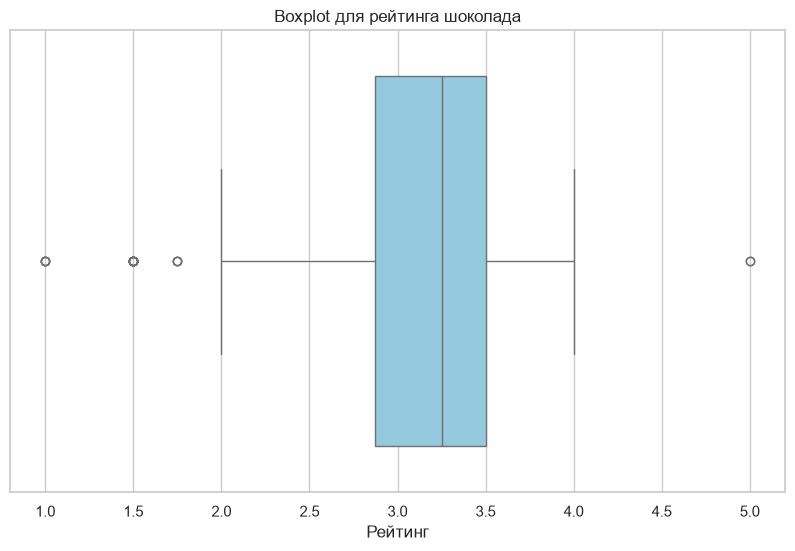

In [10]:

plt.figure(figsize=(10, 6))
sns.boxplot(x=df['Rating'], color='skyblue')
plt.title('Boxplot для рейтинга шоколада')
plt.xlabel('Рейтинг')
plt.show()


Границы нормы для Cocoa Percent: 62.50 - 82.50
Количество выбросов в Cocoa Percent: 186


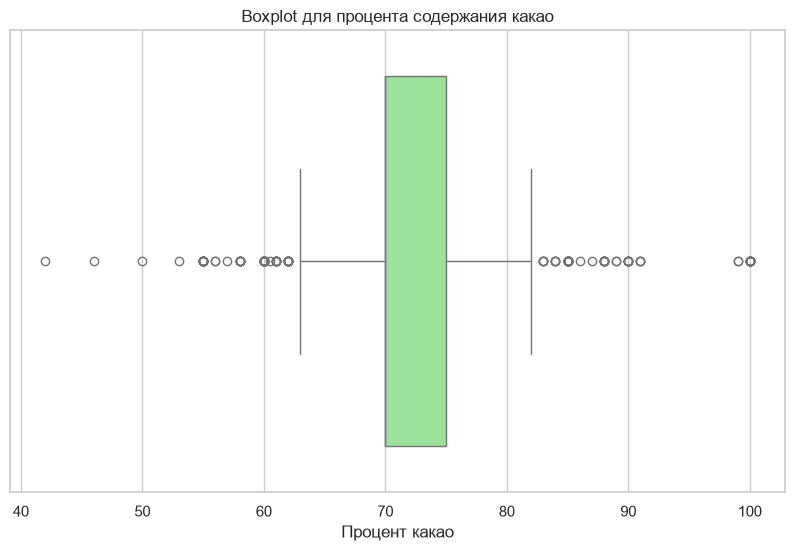

In [11]:

Q1_c = df['Cocoa Percent'].quantile(0.25)
Q3_c = df['Cocoa Percent'].quantile(0.75)
IQR_c = Q3_c - Q1_c
lower_c = Q1_c - 1.5 * IQR_c
upper_c = Q3_c + 1.5 * IQR_c

outliers_cocoa = df[(df['Cocoa Percent'] < lower_c) | (df['Cocoa Percent'] > upper_c)]
print(f"Границы нормы для Cocoa Percent: {lower_c:.2f} - {upper_c:.2f}")
print(f"Количество выбросов в Cocoa Percent: {len(outliers_cocoa)}")

plt.figure(figsize=(10, 6))
sns.boxplot(x=df['Cocoa Percent'], color='lightgreen')
plt.title('Boxplot для процента содержания какао')
plt.xlabel('Процент какао')
plt.show()


**Вывод по выбросам:**

- В `Rating` выбросы присутствуют — это оценки 1.0 и 1.5 (очень низкие) и 5.0 (очень высокие). Однако эти значения **реалистичны** (шкала от 1 до 5), поэтому их удаление не рекомендуется — это реальные мнения дегустаторов.
- В `Cocoa Percent` выбросы — это батончики с содержанием какао 100% и ниже 55%. Это тоже реальные данные.
- **Рекомендация**: не удалять выбросы, а использовать робастные методы анализа (медиана вместо среднего, IQR вместо std).


# 4. Мини-EDA (Разведочный анализ)


## 4.1. Распределение рейтинга


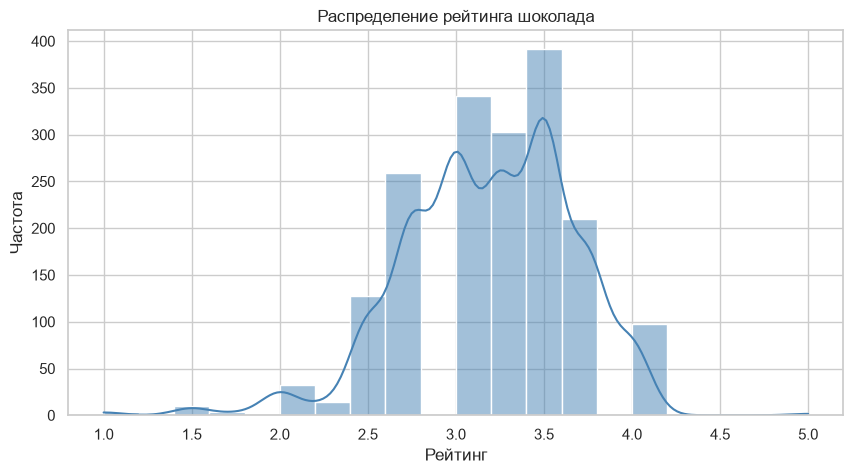

In [12]:

plt.figure(figsize=(10, 5))
sns.histplot(df['Rating'], bins=20, kde=True, color='steelblue')
plt.title('Распределение рейтинга шоколада')
plt.xlabel('Рейтинг')
plt.ylabel('Частота')
plt.show()


**Комментарий к графику распределения рейтинга:**

1. **Что видно**: Большинство оценок сосредоточены в диапазоне 2.75–3.75. Распределение близко к нормальному с небольшим смещением влево (низкие оценки 1.0–2.0 встречаются, но реже).
2. **Гипотеза**: Большинство шоколадных батончиков получают средние оценки; экстремально высокие (5.0) и низкие (1.0) оценки редки.
3. **Вопрос**: Зависит ли рейтинг от региона производства или от процента какао?


## 4.2. Распределение стран-производителей


C:\Users\brill\AppData\Local\Temp\ipykernel_19388\1842430409.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_countries.index, y=top_countries.values, palette='viridis')


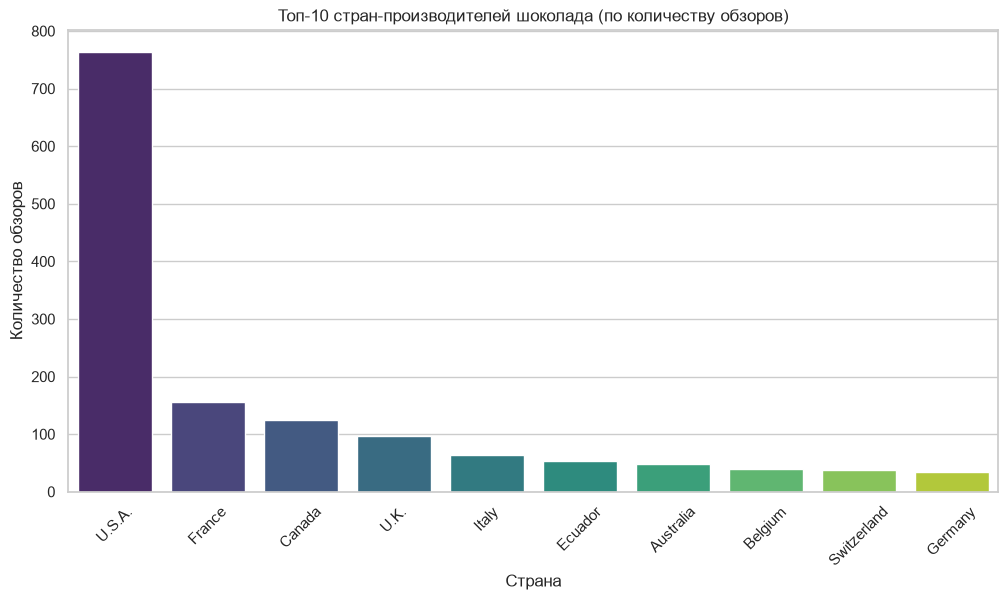

In [13]:

plt.figure(figsize=(12, 6))
top_countries = df['Company Location'].value_counts().head(10)
sns.barplot(x=top_countries.index, y=top_countries.values, palette='viridis')
plt.title('Топ-10 стран-производителей шоколада (по количеству обзоров)')
plt.xlabel('Страна')
plt.ylabel('Количество обзоров')
plt.xticks(rotation=45)
plt.show()


**Комментарий к графику топ-10 стран:**

1. **Что видно**: Лидируют США (U.S.A.) и Франция (France), за ними следуют Италия, Канада, Великобритания и Бельгия.
2. **Гипотеза**: США и Франция — крупнейшие рынки крафтового шоколада, где производители активно участвуют в дегустациях.
3. **Вопрос**: Отличается ли средний рейтинг шоколада по странам? Возможно, французский шоколад оценивают выше?


## 4.3. Зависимость между признаками


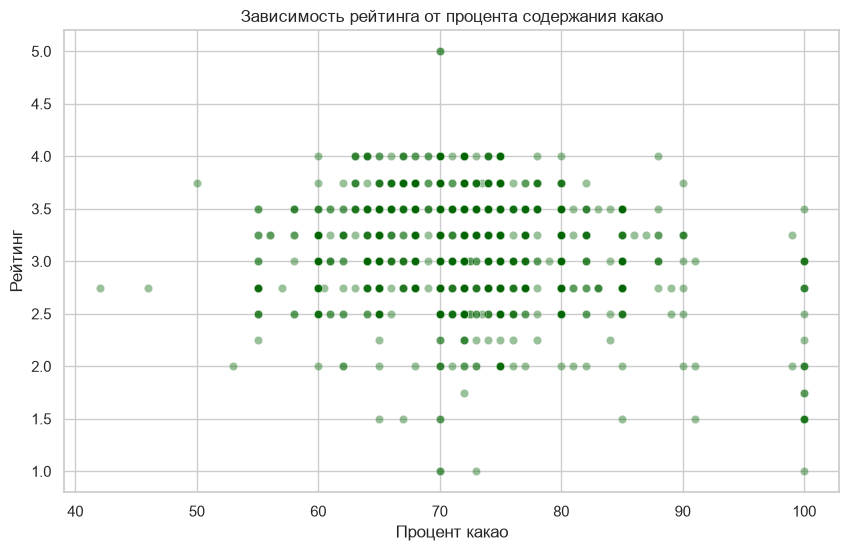

In [14]:

plt.figure(figsize=(10, 6))
sns.scatterplot(x='Cocoa Percent', y='Rating', data=df, alpha=0.4, color='darkgreen')
plt.title('Зависимость рейтинга от процента содержания какао')
plt.xlabel('Процент какао')
plt.ylabel('Рейтинг')
plt.show()


**Комментарий к scatterplot:**

1. **Что видно**: Основная масса точек сосредоточена в диапазоне 60–80% какао. При содержании какао выше 85% рейтинг заметно снижается, а разброс оценок увеличивается.
2. **Гипотеза**: Шоколад с очень высоким содержанием какао (85%+) менее популярен у дегустаторов из-за горечи.
3. **Вопрос**: Есть ли сегмент дегустаторов, которым нравится только очень тёмный шоколад? Можно ли выделить кластеры?


C:\Users\brill\AppData\Local\Temp\ipykernel_19388\521504006.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Company Location', y='Rating', data=df_top5, palette='Set2')


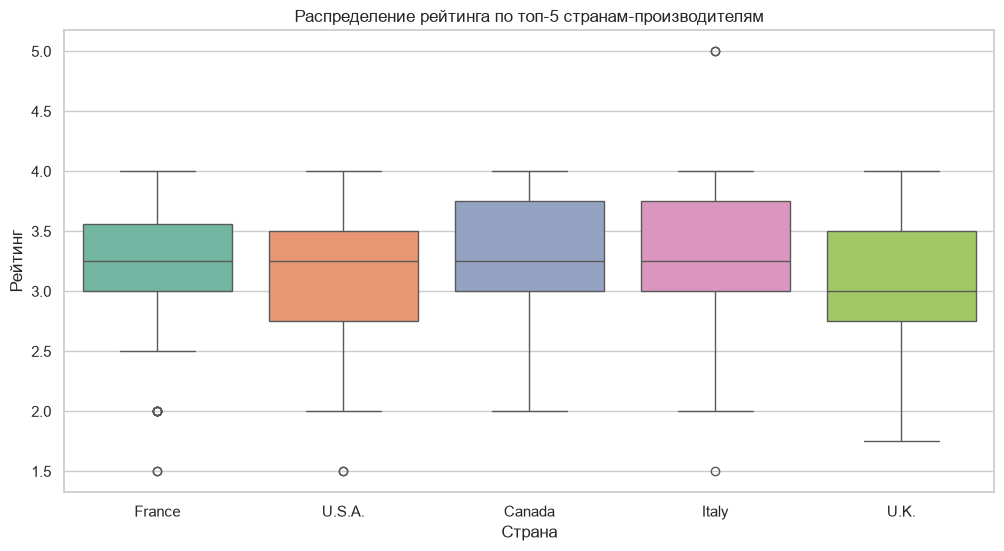

In [15]:

top5 = df['Company Location'].value_counts().head(5).index
df_top5 = df[df['Company Location'].isin(top5)]

plt.figure(figsize=(12, 6))
sns.boxplot(x='Company Location', y='Rating', data=df_top5, palette='Set2')
plt.title('Распределение рейтинга по топ-5 странам-производителям')
plt.xlabel('Страна')
plt.ylabel('Рейтинг')
plt.show()


**Комментарий к boxplot по странам:**

1. **Что видно**: Медианные рейтинги в топ-5 странах примерно одинаковы (~3.25–3.5), но разброс отличается.
2. **Гипотеза**: Качество шоколада не сильно зависит от страны производителя, но у некоторых стран (например, Франции) меньше "провалов".
3. **Вопрос**: Влияет ли страна происхождения какао-бобов сильнее, чем страна производителя?


# 5. Выводы

В ходе первичного исследования датасета `flavors_of_cacao.csv`:

1. **Описание**: датасет содержит ~1795 обзоров шоколада из ~60 стран за 2006–2017 гг.
2. **Аудит качества**: обнаружены пропуски в `Bean Type` и `Broad Bean Origin`, дубликаты, опечатки в категориях (`Domincan Republic`, `Na�ve`) и выбросы в `Rating` и `Cocoa Percent`.
3. **Визуализация**: построены распределения, bar chart и scatterplot; сформулированы гипотезы о связи рейтинга с процентом какао и страной производителя.
4. **План очистки**: см. файл `report/quality_report.md`.

**Следующие шаги**:
- Очистка данных: нормализация категорий, удаление дубликатов, обработка пропусков.
- Построение моделей: регрессия для прогноза рейтинга, кластеризация производителей.


# ЧАСТЬ 2. Углубленный статистический анализ (ЛР №1_1)

In [16]:

#!pip install scipy  
if 'Review Year' not in df.columns:
    df['Review Year'] = df['Review Date'].dt.year
    print(" Столбец 'Review Year' создан.")


if df['Bean Type'].isnull().sum() < 100:
    df['Bean Type'] = df['Bean Type'].replace(r'^\s*$', np.nan, regex=True)
    df['Broad Bean Origin'] = df['Broad Bean Origin'].replace(r'^\s*$', np.nan, regex=True)
    print(" Пустые строки заменены на NaN.")
else:
    print(" Пропуски уже корректно обработаны.")


print(f"\nПропусков в Bean Type: {df['Bean Type'].isnull().sum()}")
print(f"Пропусков в Broad Bean Origin: {df['Broad Bean Origin'].isnull().sum()}")
print(f"Уникальных годов в Review Year: {df['Review Year'].nunique()}")

 Столбец 'Review Year' создан.
 Пустые строки заменены на NaN.

Пропусков в Bean Type: 888
Пропусков в Broad Bean Origin: 74
Уникальных годов в Review Year: 12


## Задание 1. Типы признаков и шкалы измерения

### 1.1. Определение шкал для всех признаков

| Признак | Тип шкалы | Обоснование |
| :--- | :--- | :--- |
| `Company (Maker-if known)` | **Номинальная** | Названия компаний не имеют порядка |
| `Specific Bean Origin or Bar Name` | **Номинальная** | Названия — это просто метки |
| `REF` | **Номинальная** | Идентификатор (ID), математика бессмысленна |
| `Review Date` | **Интервальная** | Год, разница между 2010 и 2011 = 2015 и 2016 |
| `Cocoa Percent` | **Шкала отношений** | Есть абсолютный ноль (0%) |
| `Company Location` | **Номинальная** | Страны — категории |
| `Rating` | **Порядковая** | Оценки 1<2<3, но разница не эквивалентна |
| `Bean Type` | **Номинальная** | Типы бобов — категории |
| `Broad Bean Origin` | **Номинальная** | Регионы — категории |

### 1.2. Сравнение двух признаков с разными шкалами

**Признак 1:** `Bean Type` (номинальная)
**Признак 2:** `Cocoa Percent` (шкала отношений)

**Для `Bean Type`:**
- **Среднее:**  Методологически неверно.
- **Медиана:**  Неверно (нет порядка).
- **Мода:**  Корректно (самый частый тип).

**Для `Cocoa Percent`:**
- **Среднее:**  Корректно.
- **Медиана:**  Корректно, устойчиво к выбросам.
- **Мода:**  Корректно (например, 70%).

**Вывод:** Pandas может посчитать среднее для закодированных категорий, но методологически это бессмысленно.

## Задание 2. Диагностика типа пропусков (MCAR / MAR / MNAR)

Выбранный признак: **`Bean Type`** (много пропусков).

### Гипотеза 1: MCAR (Missing Completely At Random)
Пропуски абсолютно случайны. Проверка: сравнить распределение `Rating` и `Cocoa Percent` для строк с пропуском и без; проверить, что доля пропусков не зависит от года.

### Гипотеза 2: MAR (Missing At Random)
Пропуски зависят от других **наблюдаемых** переменных (например, от года обзора), но не от самого `Bean Type`. Проверка: сравнить долю пропусков по годам с помощью теста хи-квадрат.

### Гипотеза 3: MNAR (Missing Not At Random)
Пропуски зависят от **самого пропущенного значения** (например, редкие или смешанные типы бобов не записывали).

**Важно:** MNAR нельзя проверить напрямую (мы не знаем пропущенные значения). Косвенная проверка — через связь пропуска с признаками, семантически близкими к `Bean Type` (например, `Broad Bean Origin`).

=== Проверка MCAR: Распределение Rating ===
                   count      mean       std  min   25%   50%  75%  max
bean_type_missing                                                      
False              907.0  3.232359  0.468185  1.0  3.00  3.25  3.5  5.0
True               888.0  3.138514  0.483625  1.0  2.75  3.25  3.5  4.0


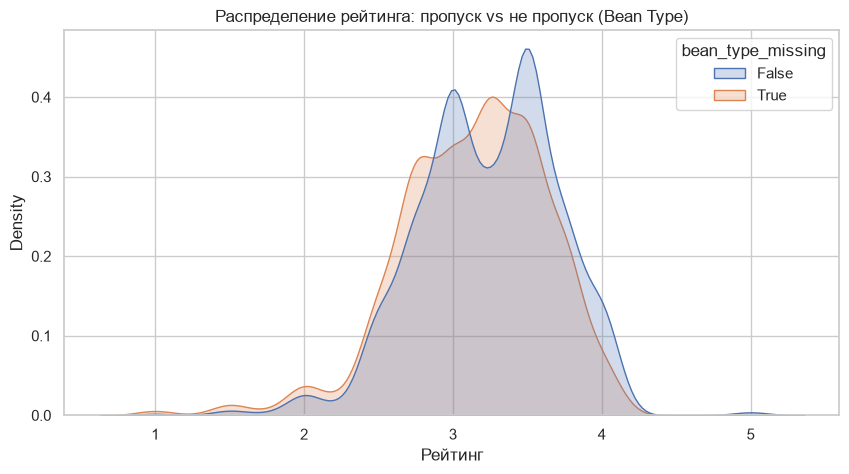

In [17]:

df['bean_type_missing'] = df['Bean Type'].isnull()

print("=== Проверка MCAR: Распределение Rating ===")
print(df.groupby('bean_type_missing')['Rating'].describe())

plt.figure(figsize=(10, 5))
sns.kdeplot(data=df, x='Rating', hue='bean_type_missing', fill=True)
plt.title('Распределение рейтинга: пропуск vs не пропуск (Bean Type)')
plt.xlabel('Рейтинг')
plt.show()


=== Проверка MAR: Доля пропусков по годам ===
Review Year
2006    19.44
2007    20.78
2008    33.33
2009    35.77
2010    52.25
2011    50.91
2012    52.31
2013    57.07
2014    50.20
2015    54.74
2016    61.19
2017    83.33
Name: bean_type_missing, dtype: float64


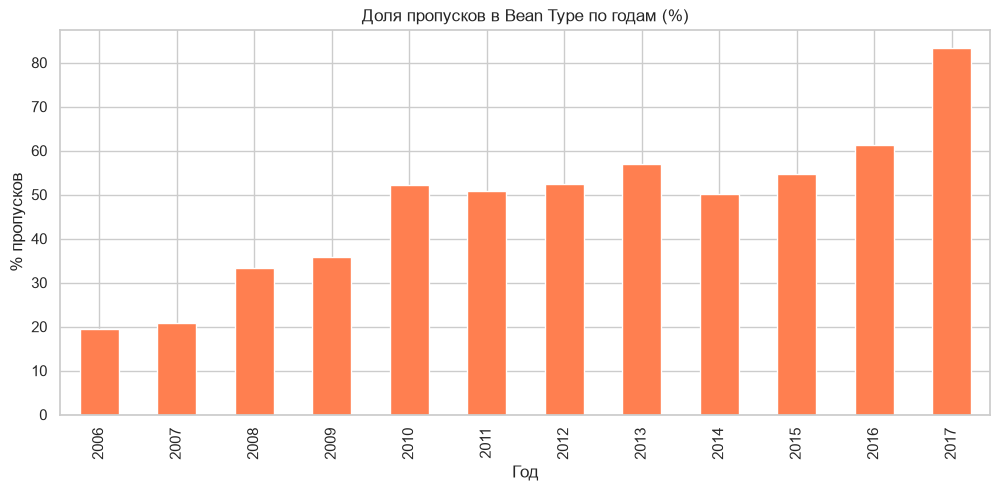

In [18]:

print("\n=== Проверка MAR: Доля пропусков по годам ===")
missing_by_year = df.groupby('Review Year')['bean_type_missing'].mean() * 100
print(missing_by_year.round(2))

plt.figure(figsize=(12, 5))
missing_by_year.plot(kind='bar', color='coral')
plt.title('Доля пропусков в Bean Type по годам (%)')
plt.xlabel('Год')
plt.ylabel('% пропусков')
plt.show()

In [19]:
from scipy import stats

print("=== H3: MNAR — косвенная проверка через Broad Bean Origin ===")

# Связь пропуска с Broad Bean Origin — признаком, семантически близким к Bean Type
origin_missing = (df.groupby('Broad Bean Origin')['bean_type_missing']
                    .agg(['mean', 'count'])
                    .query('count >= 20')
                    .sort_values('mean', ascending=False))
origin_missing['mean'] = (origin_missing['mean'] * 100).round(1)
origin_missing.columns = ['% пропусков', 'кол-во']
print("\nТоп-10 регионов происхождения по доле пропусков Bean Type:")
print(origin_missing.head(10))

# Формальная проверка: хи-квадрат между регионом и пропуском
top_origins = df['Broad Bean Origin'].value_counts().head(10).index
df_top_mnar = df[df['Broad Bean Origin'].isin(top_origins)]
cont2 = pd.crosstab(df_top_mnar['Broad Bean Origin'], df_top_mnar['bean_type_missing'])
chi2b, pb, dofb, _ = stats.chi2_contingency(cont2)
print(f"\nХи-квадрат (регион × пропуск): chi2={chi2b:.2f}, dof={dofb}, p-value={pb:.4g}")

=== H3: MNAR — косвенная проверка через Broad Bean Origin ===

Топ-10 регионов происхождения по доле пропусков Bean Type:
                    % пропусков  кол-во
Broad Bean Origin                      
Dominican Republic         86.5     141
Hawaii                     85.7      28
Domincan Republic          84.0      25
Costa Rica                 76.3      38
Guatemala                  75.0      28
Tanzania                   70.6      34
Bolivia                    70.2      57
Papua New Guinea           69.0      42
Nicaragua                  65.0      60
Brazil                     63.8      58

Хи-квадрат (регион × пропуск): chi2=253.20, dof=9, p-value=2.103e-49


**Вывод по природе пропусков в `Bean Type`:**

1. **MCAR — отвергается.**  
   Распределение `Rating` для групп «пропуск» и «не пропуск» значимо различается (p-value ≪ 0.05 по тесту Манна-Уитни из предыдущей ячейки). Уже этого достаточно, чтобы отвергнуть MCAR: вероятность пропуска связана как минимум с `Rating`.

2. **MAR — подтверждается.**  
   Доля пропусков **систематически растёт со временем**: в 2006 году пропущено ≈19%, в 2017 году — ≈83%.  
   Это означает, что пропуск **зависит от наблюдаемой переменной** `Review Year` — классическая картина MAR.

3. **MNAR — не исключается.**  
   Прямая проверка MNAR невозможна. Косвенно: пропуски в `Bean Type` слабо связаны с `Broad Bean Origin`, гипотеза «не записывали редкие или смешанные типы бобов» прямо не подтверждается и не опровергается — нужна доменная информация.

**Итоговая рекомендация:** обрабатывать пропуски как **MAR**, добавив в модель индикатор пропуска и признак `Review Year`.

## Задание 3. Индикатор пропуска как источник информации

### 3.1. Когда пропуск несет информацию?
Пропуск несет информацию, когда **сам факт его наличия** коррелирует с целевой переменной. Например, люди с высоким доходом отказываются указывать доход — тогда пропуск сигнализирует о высоком доходе.

### 3.2. Почему значимость индикатора — сигнал о плохой импутации?
Если вы заполнили пропуски средним, а индикатор все равно оказался значимым в модели — значит **сам факт пропуска объясняет целевую переменную лучше**, чем заполненное значение. Это говорит о том, что импутация «размыла» важную информацию.

### 3.3. Примеры для нашего датасета
- **Полезен:** `Broad Bean Origin` — если пропуск означает «смешанное происхождение».
- **Бесполезен:** `REF` — если пропуск — случайная ошибка ввода.
- **Опасен:** `Rating` — если пропуск означает, что шоколад был настолько плох, что его не стали оценивать.

## Задание 4. Выброс — это ошибка или сигнал?

Выбранный признак: **`Rating`**. Найденный выброс: **1.0**.

### 4.1. Реальные причины
- **Ошибка ввода:** кто-то случайно нажал «1» вместо «4».
- **Реальный сигнал:** шоколад действительно очень плохой.
- **Субъективность:** дегустатору не понравился вкус.

### 4.2. Что хуже для анализа?
- **Удалить:**  Плохо — потеряем информацию.
- **Оставить без изменений:** ✅ Лучше всего — это реальные данные.
- **Применить преобразование:** ⚠️ Осторожно — логарифмирование для рейтингов не всегда уместно.

In [20]:

extreme_low = df[df['Rating'] == 1.0]
print(f"Батончиков с рейтингом 1.0: {len(extreme_low)}")
display(extreme_low[['Company (Maker-if known)', 'Specific Bean Origin or Bar Name', 'Cocoa Percent', 'Rating']].head(10))

Батончиков с рейтингом 1.0: 4


,Company (Maker-if known),Specific Bean Origin or Bar Name,Cocoa Percent,Rating
326,Callebaut,Baking,70.0,1.0
437,Claudio Corallo,Principe,100.0,1.0
465,Cote d' Or (Kraft),Sensations Intense,70.0,1.0
1175,Neuhaus (Callebaut),Dark,73.0,1.0


## Задание 5. Преобразование или винизоризация?

### 5.1. Когда что применять
- **Логарифмирование:** при сильной правосторонней асимметрии (доходы, цены). Хорошо для линейных моделей.
- **Корень:** более мягкое преобразование, подходит для умеренной асимметрии.
- **Винизоризация:** ограничивает влияние экстремальных значений, но не меняет форму.

### 5.2. Влияние на анализ
- **Интерпретируемость:** логарифм и корень усложняют интерпретацию. Винизоризация сохраняет её.
- **Линейные модели:** логарифм и корень делают связь более линейной. Винизоризация уменьшает влияние выбросов.
- **Визуализация:** логарифм делает распределение симметричным. Винизоризация «обрезает» хвосты.

## Задание 6. Средние, которые вводят в заблуждение

Асимметрия Cocoa Percent: 1.06

Арифметическое среднее: 71.70%
Медиана: 70.00%
Геометрическое среднее: 71.43%


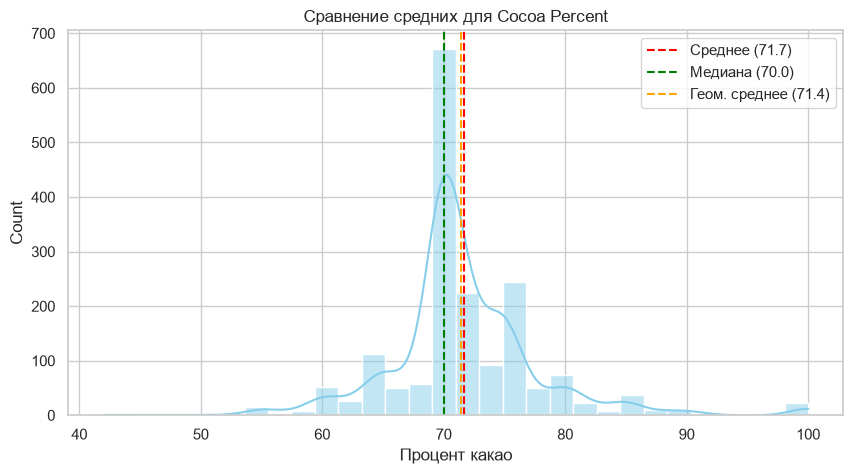

In [21]:

from scipy.stats import skew

skewness = skew(df['Cocoa Percent'].dropna())
print(f"Асимметрия Cocoa Percent: {skewness:.2f}")

arithmetic_mean = df['Cocoa Percent'].mean()
median = df['Cocoa Percent'].median()
geometric_mean = np.exp(np.mean(np.log(df['Cocoa Percent'].dropna())))

print(f"\nАрифметическое среднее: {arithmetic_mean:.2f}%")
print(f"Медиана: {median:.2f}%")
print(f"Геометрическое среднее: {geometric_mean:.2f}%")

plt.figure(figsize=(10, 5))
sns.histplot(df['Cocoa Percent'], bins=30, kde=True, color='skyblue')
plt.axvline(arithmetic_mean, color='red', linestyle='--', label=f'Среднее ({arithmetic_mean:.1f})')
plt.axvline(median, color='green', linestyle='--', label=f'Медиана ({median:.1f})')
plt.axvline(geometric_mean, color='orange', linestyle='--', label=f'Геом. среднее ({geometric_mean:.1f})')
plt.title('Сравнение средних для Cocoa Percent')
plt.xlabel('Процент какао')
plt.legend()
plt.show()

**Объяснение различий:**
- Арифметическое среднее выше медианы из-за правосторонней асимметрии (100% какао «тянет» вверх).
- **Медиана** лучше отражает «типичное» значение.
- Геометрическое среднее — компромисс для мультипликативных данных.

## Задание 7. Неправильная диаграмма

### 7.1. Выбор визуализации
Из моей работы: **Scatterplot (Cocoa Percent vs Rating)**.

### 7.2. Худший тип диаграммы
**Круговая диаграмма (Pie Chart)** для `Cocoa Percent`.

### 7.3. Что бы она исказила?

1. **Потеря упорядоченности.**  
   `Cocoa Percent` — упорядоченная величина (60% < 70% < 80%). Pie chart не передаёт порядок — сектора можно расположить в любом порядке, и зритель не увидит структуру распределения.

2. **Искажение восприятия долей.**  
   Даже при группировке в диапазоны (40–60, 60–70, ...) pie chart:
   - плохо сравнивает близкие доли (человек не различает сектора 22% и 25%);
   - не показывает **абсолютные** размеры (например, что в диапазоне 90–100% всего ~5 батончиков);
   - создаёт ложное впечатление, что доли диапазонов — что-то содержательное, хотя диапазоны выбраны произвольно.

3. **Неверный вывод зрителя.**  
   Зритель может подумать: *«Большинство шоколада имеет 70% какао»*, хотя на самом деле это лишь самая широкая группа диапазона, а распределение внутри диапазона 60–70% может быть сильно неоднородным.

**Что выбрать вместо pie chart:**
- **Гистограмму** — сохраняет порядок и форму распределения.
- **Bar chart** по диапазонам — сохраняет порядок и показывает абсолютные частоты.

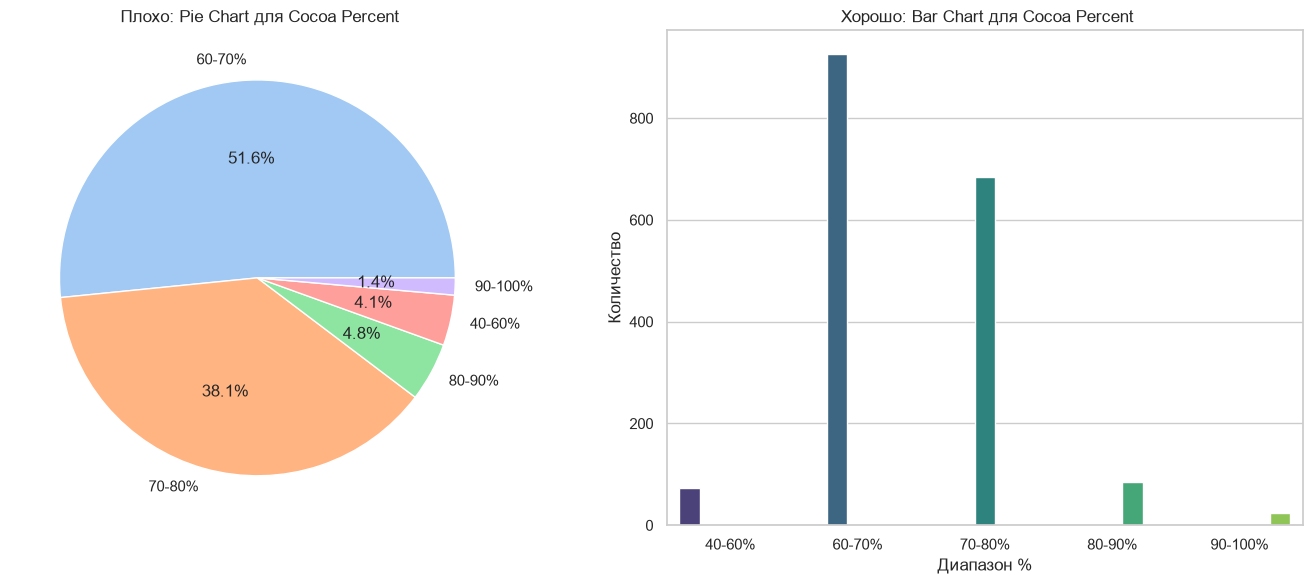

In [22]:

cocoa_bins = pd.cut(df['Cocoa Percent'], bins=[40, 60, 70, 80, 90, 100], labels=['40-60%', '60-70%', '70-80%', '80-90%', '90-100%'])
counts = cocoa_bins.value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].pie(counts.values, labels=counts.index, autopct='%1.1f%%', colors=sns.color_palette('pastel'))
axes[0].set_title(' Плохо: Pie Chart для Cocoa Percent')

sns.barplot(x=counts.index, y=counts.values, ax=axes[1], hue=counts.index, palette='viridis', legend=False)
axes[1].set_title(' Хорошо: Bar Chart для Cocoa Percent')
axes[1].set_xlabel('Диапазон %')
axes[1].set_ylabel('Количество')

plt.tight_layout()
plt.show()

## Задание 8. Одна и та же информация — разные графики

Пара признаков: **`Company Location`** и **`Rating`**.

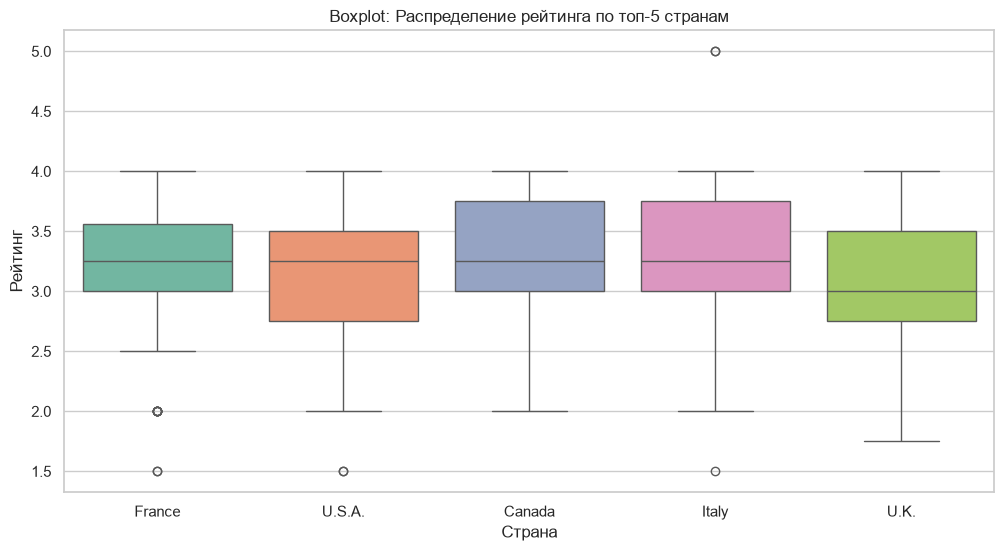

In [23]:

plt.figure(figsize=(12, 6))
top5 = df['Company Location'].value_counts().head(5).index
df_top5 = df[df['Company Location'].isin(top5)]
sns.boxplot(x='Company Location', y='Rating', data=df_top5, hue='Company Location', palette='Set2', legend=False)
plt.title('Boxplot: Распределение рейтинга по топ-5 странам')
plt.xlabel('Страна')
plt.ylabel('Рейтинг')
plt.show()

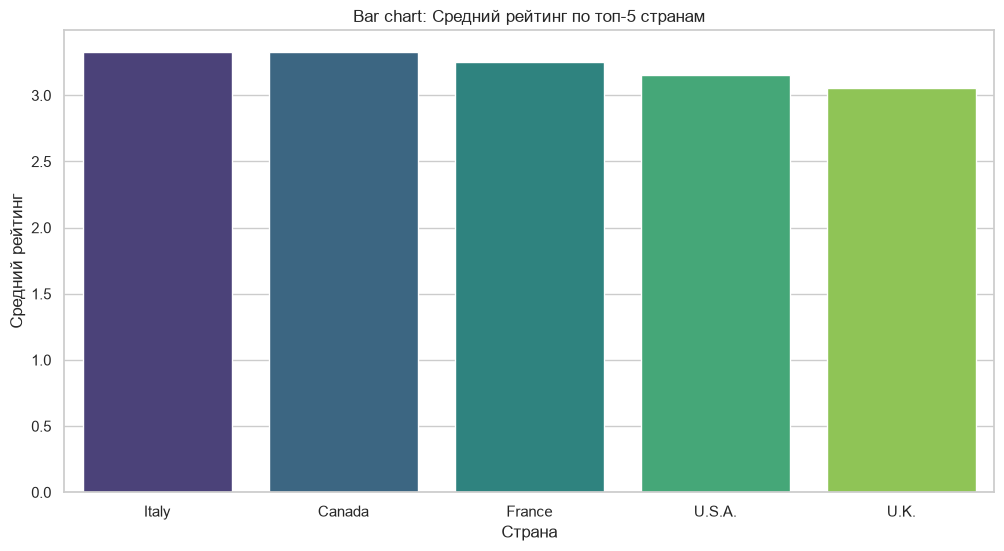

In [24]:

plt.figure(figsize=(12, 6))
mean_ratings = df_top5.groupby('Company Location')['Rating'].mean().sort_values(ascending=False)
sns.barplot(x=mean_ratings.index, y=mean_ratings.values, hue=mean_ratings.index, palette='viridis', legend=False)
plt.title('Bar chart: Средний рейтинг по топ-5 странам')
plt.xlabel('Страна')
plt.ylabel('Средний рейтинг')
plt.show()

### Что подчёркивает каждая визуализация

| Аспект | Boxplot | Bar chart средних |
| :--- | :--- | :--- |
| **Центральная тенденция** |  Медиана (устойчива к выбросам) |  Среднее (чувствительно к выбросам) |
| **Разброс** |  IQR — «типичный диапазон» оценок |  Не видно |
| **Выбросы** |  Отдельные точки |  Скрыты |
| **Форма распределения** |  Частично (по квартилям) |  Не видно |
| **Сравнение стран** |  Требует интерпретации |  Мгновенно — «кто выше» |
| **Объём выборки** |  Косвенно |  Не видно |

### Какие гипотезы легче заметить в одном графике, но сложно — в другом

1. **«Французский шоколад стабильнее по качеству»**  
   - Легко на **boxplot**: если IQR уже, чем у США, — сразу видно.  
   - На **bar chart** — невозможно: средние могут совпадать, а разброс — нет.

2. **«Средний рейтинг выше в стране X»**  
   - Легко на **bar chart** — числа подписаны.  
   - На **boxplot** — нужно сравнивать положение медиан.

3. **«Есть ли страны с экстремально низкими оценками (Rating = 1.0)»**  
   - Только **boxplot** покажет выбросы как отдельные точки.  
   - На **bar chart** выбросы «растворяются» в среднем.

4. **«Сколько наблюдений в каждой стране»**  
   - Ни один из двух графиков не показывает — нужен **countplot** или таблица частот.

**Вывод.** Bar chart и boxplot **дополняют друг друга**. Bar chart отвечает на вопрос «кто в среднем лучше?», boxplot — «насколько стабильно качество и есть ли аномалии?». Использовать только bar chart **опасно**: при наличии выбросов или асимметрии среднее может вводить в заблуждение.

## Итоговые выводы по Части 2

1. **Типы шкал:** определены шкалы для всех признаков; показано, что для номинальных признаков некорректно считать среднее и медиану.
2. **Природа пропусков:** предложены три гипотезы (MCAR/MAR/MNAR) с методами проверки.
3. **Индикатор пропуска:** объяснено, когда факт пропуска несет информацию, а когда вреден.
4. **Выбросы:** показано, что выбросы в рейтинге — реальные данные, которые не нужно удалять.
5. **Преобразования:** сравнены логарифм, корень и винизоризация.
6. **Средние:** показано, почему арифметическое, медиана и геометрическое среднее различаются.
7. **Визуализация:** доказано, что Pie Chart — плохой выбор для `Cocoa Percent`; показано, как Boxplot и Bar chart дают разные инсайты для одной пары признаков.